# Day 3 · Split Customers into Groups (K-Means)

**Campaign Segmenter, Project 1, Day 3.**

## 1. Project objective

We have 17,049 online orders from 5,000 customers. The goal is to **split the customers into a few groups that
behave differently when they buy**, so that later (Day 4) each group can get its own marketing message.

Today's checklist:
1. Clean the data with pandas
2. Pick the columns to use and scale them
3. Run K-Means for k = 2 to 8
4. Pick the best k using the elbow plot and silhouette score
5. Write one line describing each group

### The ideas behind it, in plain language

**What is clustering?** Putting similar things into the same pile without being told what the piles are.
Imagine tipping a bag of mixed buttons on a table and sorting them by size and colour. Nobody gave you the
categories; you found them by looking at how similar the buttons are.

**What is unsupervised learning?** Machine learning *without an answer column*. In *supervised* learning
you'd have a label to predict (e.g. "will this customer churn: yes/no"). Here no customer comes with a
"segment" label. The algorithm has to discover the structure from the data alone.

**What is K-Means?** The most common clustering algorithm. It works like this:
1. Drop **K** points at random into the data. These are the starting *centroids*.
2. Assign every customer to the nearest centroid.
3. Move each centroid to the **average position** of the customers assigned to it.
4. Repeat steps 2–3 until nothing changes.

**What does K represent?** The number of groups you ask for. K-Means can't choose it itself, so
we try several values (2–8) and compare.

**What is a centroid?** The centre of a group: the "average customer" of that cluster. If a cluster's
centroid has frequency = 6 and recency = 50 days, the typical member orders often and bought recently.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42          # makes K-Means give the same answer every run
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "ecommerce_customer_behavior_dataset_v2.csv"
OUT_PATH = ROOT / "data" / "processed" / "customer_segments.csv"

## 2. Dataset loading

The raw file has **one row per order**, not per customer. We only read it. The original CSV is never
modified, and every change happens on a copy in memory.

In [2]:
raw = pd.read_csv(DATA_PATH, parse_dates=["Date"])
print("shape (rows, columns):", raw.shape)
raw.head()

shape (rows, columns): (17049, 18)


,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_000001-1,CUST_00001,2023-05-29,40,Male,Ankara,Books,29.18,1,0.00,29.18,Digital Wallet,Mobile,14,9,True,13,4
1,ORD_000001-2,CUST_00001,2023-10-12,40,Male,Ankara,Home & Garden,644.40,1,138.05,506.35,Credit Card,Desktop,14,8,True,6,2
2,ORD_000001-3,CUST_00001,2023-12-05,40,Male,Ankara,Sports,332.82,5,0.00,1664.10,Credit Card,Mobile,15,10,True,9,4
3,ORD_000002-1,CUST_00002,2023-05-11,33,Male,Istanbul,Food,69.30,5,71.05,275.45,Digital Wallet,Desktop,16,13,True,4,4
4,ORD_000002-2,CUST_00002,2023-06-16,33,Male,Istanbul,Beauty,178.15,3,0.00,534.45,Credit Card,Mobile,14,7,True,6,4


## 3. Data exploration

First questions to ask any dataset: what columns are there, what types, how many unique customers,
and what do the numbers look like?

In [3]:
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique_values": raw.nunique(),
})
overview

,dtype,missing,unique_values
Order_ID,str,0,17049
Customer_ID,str,0,5000
Date,datetime64[us],0,450
Age,int64,0,57
Gender,str,0,3
City,str,0,10
Product_Category,str,0,8
Unit_Price,float64,0,14711
Quantity,int64,0,5
Discount_Amount,float64,0,5526


In [4]:
print("orders:", len(raw), "| customers:", raw["Customer_ID"].nunique())
print("date range:", raw["Date"].min().date(), "->", raw["Date"].max().date())
print("orders per customer:")
print(raw.groupby("Customer_ID").size().describe().round(2).to_string())

orders: 17049 | customers: 5000
date range: 2023-01-01 -> 2024-03-25
orders per customer:
count    5000.00
mean        3.41
std         2.18
min         1.00
25%         2.00
50%         3.00
75%         5.00
max        10.00


In [5]:
raw.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
Date,17049,2023-08-15 01:33:09.723737,2023-01-01 00:00:00,2023-04-26 00:00:00,2023-08-16 00:00:00,2023-12-06 00:00:00,2024-03-25 00:00:00,NaN
Age,17049.0,34.945745,18.0,26.0,35.0,42.0,75.0,11.046855
Unit_Price,17049.0,447.901689,5.05,73.26,174.68,494.57,7900.01,722.319705
Quantity,17049.0,3.011379,1.0,2.0,3.0,4.0,5.0,1.417027
Discount_Amount,17049.0,69.788135,0.0,0.0,0.0,32.71,6538.29,240.704662
Total_Amount,17049.0,1277.438711,6.21,172.97,455.85,1267.75,37852.05,2358.436375
Session_Duration_Minutes,17049.0,14.535633,4.0,13.0,15.0,17.0,26.0,2.925524
Pages_Viewed,17049.0,9.003109,1.0,7.0,9.0,11.0,18.0,2.259954
Delivery_Time_Days,17049.0,6.503607,1.0,4.0,6.0,8.0,25.0,3.488787
Customer_Rating,17049.0,3.899408,1.0,3.0,4.0,5.0,5.0,1.128803


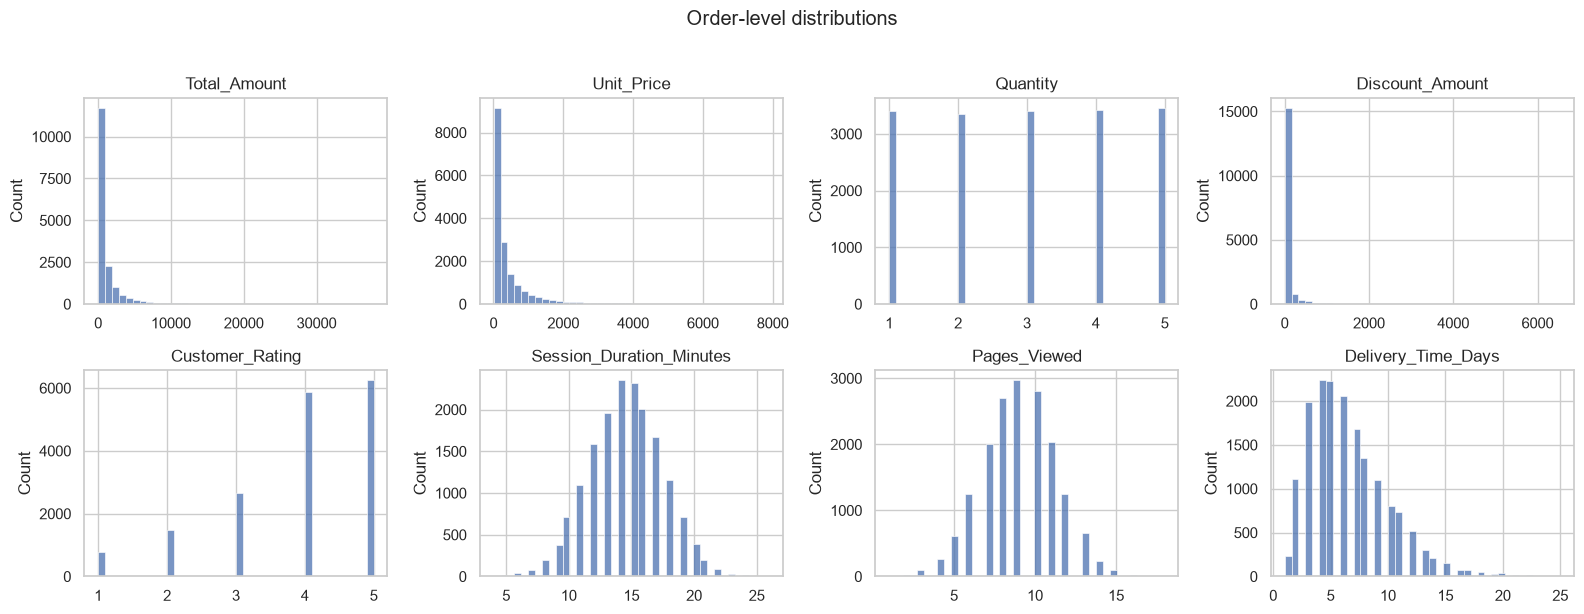

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.ravel(), ["Total_Amount", "Unit_Price", "Quantity", "Discount_Amount",
                                  "Customer_Rating", "Session_Duration_Minutes", "Pages_Viewed", "Delivery_Time_Days"]):
    sns.histplot(raw[col], bins=40, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.suptitle("Order-level distributions", y=1.02)
plt.tight_layout()
plt.show()

**What this shows:**
- **5,000 customers, 1–10 orders each** (3.4 on average). We'll need to roll orders up to customers.
- `Total_Amount` and `Unit_Price` are **heavily right-skewed**: most orders are a few hundred, but a
  few are tens of thousands. That matters later, because K-Means is sensitive to extreme values.
- `Session_Duration_Minutes`, `Pages_Viewed` and `Delivery_Time_Days` look like bell curves around a
  centre with no obvious sub-groups.
- `Product_Category` has 8 values and `Customer_Rating` is 1–5.

## 4. Data cleaning

We **check** everything, but only **change** something when there's a reason. Deleting rows
"to be safe" throws away real customers.

In [7]:
df = raw.copy()   # work on a copy; the original stays untouched

checks = {
    "missing values (all columns)": int(df.isna().sum().sum()),
    "fully duplicated rows": int(df.duplicated().sum()),
    "duplicated Order_ID": int(df["Order_ID"].duplicated().sum()),
    "rows duplicated if we ignore Order_ID": int(df.drop(columns="Order_ID").duplicated().sum()),
    "negative numbers": int((df.select_dtypes("number") < 0).sum().sum()),
    "Quantity < 1": int((df["Quantity"] < 1).sum()),
    "Unit_Price <= 0": int((df["Unit_Price"] <= 0).sum()),
    "Customer_Rating outside 1-5": int((~df["Customer_Rating"].between(1, 5)).sum()),
    "Discount bigger than price x quantity": int((df["Discount_Amount"] > df["Unit_Price"] * df["Quantity"]).sum()),
    "Total != price x qty - discount (by > 1 cent)": int(
        ((df["Unit_Price"] * df["Quantity"] - df["Discount_Amount"] - df["Total_Amount"]).abs() > 0.01).sum()),
}
pd.Series(checks, name="problem rows").to_frame()

,problem rows
missing values (all columns),0
fully duplicated rows,0
duplicated Order_ID,0
rows duplicated if we ignore Order_ID,0
negative numbers,0
Quantity < 1,0
Unit_Price <= 0,0
Customer_Rating outside 1-5,0
Discount bigger than price x quantity,0
Total != price x qty - discount (by > 1 cent),0


In [8]:
# Attributes that describe the PERSON should be identical on every order of that customer
per_customer = df.groupby("Customer_ID")
consistency = {col: int((per_customer[col].nunique() > 1).sum())
               for col in ["Age", "Gender", "City", "Is_Returning_Customer"]}
pd.Series(consistency, name="customers with >1 value").to_frame()

,customers with >1 value
Age,0
Gender,0
City,0
Is_Returning_Customer,1661


In [9]:
# How many orders are 'outliers' by the usual 1.5 x IQR rule?
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return int((s > q3 + 1.5 * (q3 - q1)).sum())

out = pd.Series({c: iqr_outliers(df[c]) for c in ["Total_Amount", "Unit_Price", "Discount_Amount"]}, name="IQR outliers")
print(out.to_string())
print("\nMedian unit price by category:")
print(df.groupby("Product_Category")["Unit_Price"].median().sort_values(ascending=False).round(2).to_string())

Total_Amount       1943
Unit_Price         1757
Discount_Amount    2789

Median unit price by category:
Product_Category
Electronics      1431.85
Home & Garden     588.65
Sports            406.83
Fashion           228.58
Toys              140.31
Beauty             96.31
Food               57.93
Books              48.41


### Cleaning decisions (and why)

| Check | Result | Decision |
|---|---|---|
| Missing values | 0 | Nothing to fill. |
| Duplicate rows / Order_IDs | 0 / 0 | Nothing to remove. Even ignoring `Order_ID`, no two orders are identical. |
| Invalid numbers (negatives, qty < 1, rating outside 1–5) | 0 | Nothing to fix. |
| `Total = Unit_Price × Quantity − Discount` | holds on every row | The money columns are internally consistent, so we can trust them. |
| Age, Gender, City per customer | always consistent | These describe the person, as expected. |
| `Is_Returning_Customer` | **changes between orders for 1,661 customers** | It's a per-*order* flag ("was this a repeat purchase?"), not a property of the customer. We **don't use it**: order count (frequency) captures the same idea more precisely. |
| ~1,900 "outlier" orders by IQR | kept | These are **real expensive purchases**: Electronics has a median unit price of ~1,432 vs ~48 for Books. Deleting them would delete the best customers. Instead we'll reduce their pull with a **log transform** (section 6). |

**Bottom line:** the data is already clean. The only real work is reshaping it from orders to customers.

## 5. Feature selection

### Step 1: one row per customer

K-Means must compare **customers**, but the file has **orders**. A customer with 10 orders would
otherwise count 10 times. So we **aggregate**: group the rows by `Customer_ID` and summarise each customer.

`Customer_ID` is only the grouping key. It is **not** a feature: it's an arbitrary label, and
"CUST_04000" isn't "bigger" than "CUST_00001" in any meaningful way.

In [10]:
reference_date = df["Date"].max() + pd.Timedelta(days=1)   # "today" = the day after the last order
df["Gross_Amount"] = df["Unit_Price"] * df["Quantity"]      # price before discount

customers = df.groupby("Customer_ID").agg(
    frequency=("Order_ID", "count"),
    total_spend=("Total_Amount", "sum"),
    avg_order_value=("Total_Amount", "mean"),
    avg_quantity=("Quantity", "mean"),
    avg_unit_price=("Unit_Price", "mean"),
    total_discount=("Discount_Amount", "sum"),
    gross_amount=("Gross_Amount", "sum"),
    avg_rating=("Customer_Rating", "mean"),
    avg_session_minutes=("Session_Duration_Minutes", "mean"),
    avg_pages_viewed=("Pages_Viewed", "mean"),
    avg_delivery_days=("Delivery_Time_Days", "mean"),
    last_order=("Date", "max"),
)
customers["recency_days"] = (reference_date - customers["last_order"]).dt.days
customers["discount_rate"] = customers["total_discount"] / customers["gross_amount"]  # share of list price given away
customers = customers.drop(columns=["last_order", "gross_amount"])

print(customers.shape, "-> one row per customer")
customers.head()

(5000, 12) -> one row per customer


,frequency,total_spend,avg_order_value,avg_quantity,avg_unit_price,total_discount,avg_rating,avg_session_minutes,avg_pages_viewed,avg_delivery_days,recency_days,discount_rate
Customer_ID,,,,,,,,,,,,
CUST_00001,3,2199.63,733.210000,2.333333,335.466667,138.05,3.333333,14.333333,9.000000,9.333333,112,0.059054
CUST_00002,2,809.90,404.950000,4.000000,123.725000,71.05,4.000000,15.000000,10.000000,5.000000,284,0.080652
CUST_00003,2,3030.81,1515.405000,3.500000,362.565000,0.00,3.500000,10.500000,8.500000,6.000000,83,0.000000
CUST_00004,1,383.22,383.220000,5.000000,96.200000,97.78,5.000000,16.000000,15.000000,4.000000,42,0.203285
CUST_00005,3,2422.73,807.576667,2.666667,378.736667,0.00,3.666667,12.666667,9.333333,5.666667,279,0.000000


**Key lines explained:**
- `df.groupby("Customer_ID").agg(...)` creates one pile per customer, then for each pile computes a number:
  `"count"` of orders, `"sum"` of money, `"mean"` of quantity and so on.
- **Recency** = days between the customer's last order and the day after the last order in the data. Small = bought recently.
- **Discount rate** = total discount ÷ total list price. 0.10 means they paid 10% below list price on average.
  A *rate* is better than a raw discount *amount*, which just grows with how much someone spends.

### Step 2: choose which columns go into K-Means

Every column we feed in has an equal say in deciding who is "similar". Columns that are
**redundant** count the same idea twice, and columns that are **pure noise** blur the groups.
Let's look at the correlations between the candidate features.

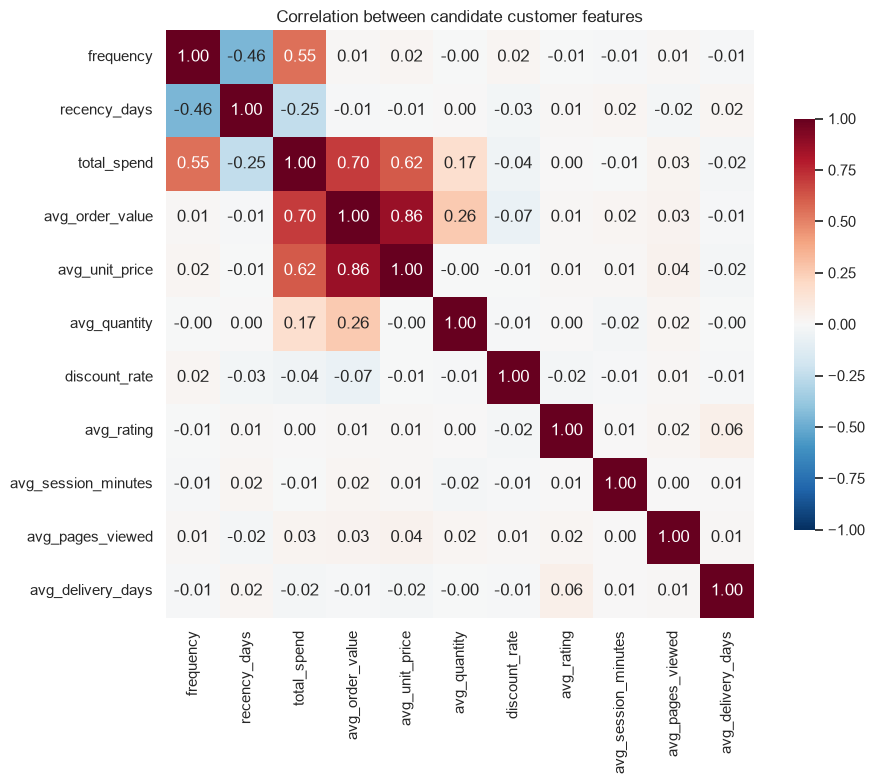

In [11]:
candidates = ["frequency", "recency_days", "total_spend", "avg_order_value", "avg_unit_price", "avg_quantity",
              "discount_rate", "avg_rating", "avg_session_minutes", "avg_pages_viewed", "avg_delivery_days"]
corr = customers[candidates].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7})
plt.title("Correlation between candidate customer features")
plt.tight_layout()
plt.show()

In [12]:
# Largest absolute correlation each feature has with any OTHER feature
max_corr = corr.abs().where(~np.eye(len(corr), dtype=bool)).max().round(2).sort_values()
max_corr.to_frame("max |correlation| with another feature")

,max |correlation| with another feature
avg_session_minutes,0.02
avg_pages_viewed,0.04
avg_rating,0.06
avg_delivery_days,0.06
discount_rate,0.07
avg_quantity,0.26
recency_days,0.46
frequency,0.55
total_spend,0.70
avg_order_value,0.86


**What the heatmap tells us:**
- `avg_unit_price` ↔ `avg_order_value`: **0.86**. Nearly the same information (order value ≈ price × quantity), so we keep one.
- `total_spend` is built from `frequency` × `avg_order_value` (correlations 0.55 and 0.70). Using all three
  would count spending twice, so we keep the two *ingredients* and use total spend only to **describe** groups.
- `frequency` ↔ `recency_days`: −0.46. Related (frequent buyers tend to have bought recently) but not the same,
  so we keep both. Together with order value they form the classic **RFM** view (Recency, Frequency, Monetary).
- `avg_rating`, `avg_session_minutes`, `avg_pages_viewed`, `avg_delivery_days` have **almost no
  relationship with anything** (all |r| ≤ 0.06). They don't describe *how people buy*, and they behave like
  independent noise. A quick test (section 7) shows that adding them **lowers** cluster quality.
  We keep them only for **describing** the groups afterwards.

### Final features

| Feature | Meaning | Why it's useful for marketing |
|---|---|---|
| `frequency` | number of orders | Loyalty: who keeps coming back |
| `recency_days` | days since last order | Who is active vs drifting away (win-back targets) |
| `avg_order_value` | average spend per order (from `Total_Amount`) | Who buys big baskets vs small ones |
| `avg_quantity` | average items per order | Bulk buyers vs single-item buyers |
| `discount_rate` | share of list price discounted | Who is price/promo-sensitive |

None are categorical, so no arbitrary number-encoding of things like City or Category is needed.
`Product_Category` is used later to describe each group.

In [13]:
FEATURES = ["frequency", "recency_days", "avg_order_value", "avg_quantity", "discount_rate"]
customers[FEATURES].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
frequency,5000.0,3.410,2.182,1.00,2.000,3.000,5.000,10.000
recency_days,5000.0,125.716,108.051,1.00,39.000,94.000,185.000,450.000
avg_order_value,5000.0,1262.886,1539.039,14.28,387.122,794.482,1550.695,25314.075
avg_quantity,5000.0,3.012,0.947,1.00,2.421,3.000,3.600,5.000
discount_rate,5000.0,0.052,0.057,0.00,0.000,0.031,0.091,0.220


## 6. Feature scaling

**Why scale?** K-Means measures similarity as **distance**. Our features live on wildly different scales:
order value runs from 14 to 25,314, while discount rate runs from 0 to 0.22. Without scaling, a 100-unit
difference in order value would swamp *any* difference in discount rate, and K-Means would cluster
on order value alone.

**What is StandardScaler?** It rescales each column to **mean 0 and standard deviation 1**:

$$z = \frac{x - \text{mean}}{\text{standard deviation}}$$

After scaling, "1" means "one standard deviation above average" for *every* feature, so each has a fair vote.

**Log transform first.** `avg_order_value` is extremely skewed (skewness ≈ 4). A few huge spenders would sit
so far away that they'd pull a centroid towards themselves. `np.log1p(x)` (= log(1 + x)) squeezes the
long tail while keeping the order. A 10× bigger order becomes "+2.3", not "+10×". We keep every customer;
we just measure order value on a ratio scale.

In [14]:
X = customers[FEATURES].copy()
print("skewness before log:", round(X["avg_order_value"].skew(), 2))
X["avg_order_value"] = np.log1p(X["avg_order_value"])
print("skewness after log: ", round(X["avg_order_value"].skew(), 2))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)          # learns mean/std of each column, then applies z = (x - mean) / std

pd.DataFrame(X_scaled, columns=FEATURES).describe().T[["mean", "std", "min", "max"]].round(3)

skewness before log: 4.17
skewness after log:  -0.22


,mean,std,min,max
frequency,-0.0,1.0,-1.105,3.021
recency_days,0.0,1.0,-1.154,3.002
avg_order_value,0.0,1.0,-3.725,3.348
avg_quantity,-0.0,1.0,-2.126,2.100
discount_rate,0.0,1.0,-0.910,2.967


After scaling, every feature has mean 0 and standard deviation 1, which is exactly what we wanted.

## 7. K-Means clustering for K = 2 to 8

For each K we train a separate model and record two scores.

**Inertia** = the sum of squared distances from every customer to its own centroid. It measures how
*tight* the groups are (lower = tighter). Catch: inertia **always** goes down as K goes up. With
K = 5,000 every customer is its own group and inertia is 0. So "lowest inertia" can't pick K on its own.

**Silhouette score** asks every customer: *"Am I much closer to my own group than to the next-nearest group?"*
- **+1**: perfectly inside its own group, far from the others
- **0**: sitting on the border between two groups
- **negative**: probably in the wrong group

The score is the average over all customers. Unlike inertia it doesn't automatically improve with more K,
so it can tell us when extra groups stop helping.

`n_init=10` runs K-Means 10 times from different random starts and keeps the best (lowest-inertia) result,
which protects against an unlucky start. `random_state=42` makes those starts reproducible.

In [15]:
results = []
models = {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)        # fit = find centroids; predict = assign each customer
    models[k] = km
    results.append({
        "k": k,
        "inertia": round(km.inertia_, 1),
        "silhouette": round(silhouette_score(X_scaled, labels), 4),
        "smallest_cluster": int(np.bincount(labels).min()),
        "largest_cluster": int(np.bincount(labels).max()),
    })

results = pd.DataFrame(results).set_index("k")
results["inertia_drop"] = (-results["inertia"].diff()).round(1)   # how much inertia we gain by adding one more cluster
results

,inertia,silhouette,smallest_cluster,largest_cluster,inertia_drop
k,,,,,
2,19883.3,0.2039,2039,2961,NaN
3,16658.5,0.1932,1643,1706,3224.8
4,14237.8,0.2117,1024,1433,2420.7
5,12674.3,0.2104,747,1271,1563.5
6,11609.1,0.2043,470,1131,1065.2
7,10866.6,0.2026,342,1016,742.5
8,10213.0,0.1973,361,890,653.6


**Sanity check on the feature choice.** Earlier we argued that rating, session time, pages viewed and delivery
time are noise for segmentation. Here's the evidence: the same K-Means with those four columns added.

In [16]:
WITH_NOISE = FEATURES + ["avg_rating", "avg_session_minutes", "avg_pages_viewed", "avg_delivery_days"]
X_noise = customers[WITH_NOISE].copy()
X_noise["avg_order_value"] = np.log1p(X_noise["avg_order_value"])
X_noise_scaled = StandardScaler().fit_transform(X_noise)

compare = pd.DataFrame({
    "silhouette: 5 behaviour features": results["silhouette"],
    "silhouette: + 4 engagement/service features": [
        round(silhouette_score(X_noise_scaled, KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X_noise_scaled)), 4)
        for k in range(2, 9)],
}, index=results.index)
compare

,silhouette: 5 behaviour features,silhouette: + 4 engagement/service features
k,,
2,0.2039,0.1368
3,0.1932,0.0956
4,0.2117,0.0990
5,0.2104,0.1032
6,0.2043,0.1077
7,0.2026,0.1008
8,0.1973,0.1003


Adding the four extra columns lowers the silhouette at every K, so they make the groups *less*
distinct. That confirms keeping them out of the model.

## 8. Elbow Method

**The idea:** plot inertia against K. At first, each extra cluster cuts inertia a lot (we're splitting genuinely
different customers). Later, extra clusters only shave off a little (we're splitting groups that belong together).
The **"elbow"** is the bend where the curve flattens: adding more clusters beyond it isn't worth it.

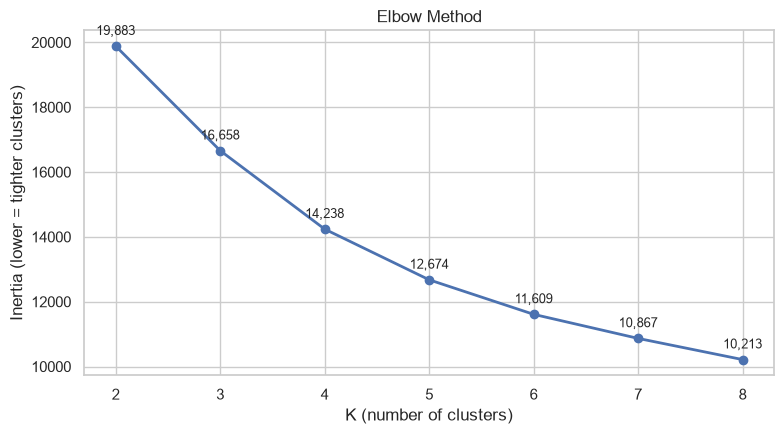

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(results.index, results["inertia"], marker="o", linewidth=2)
for k, row in results.iterrows():
    ax.annotate(f"{row['inertia']:,.0f}", (k, row["inertia"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_xlabel("K (number of clusters)")
ax.set_ylabel("Inertia (lower = tighter clusters)")
ax.set_title("Elbow Method")
ax.set_xticks(results.index)
plt.tight_layout()
plt.show()

## 9. Silhouette Score

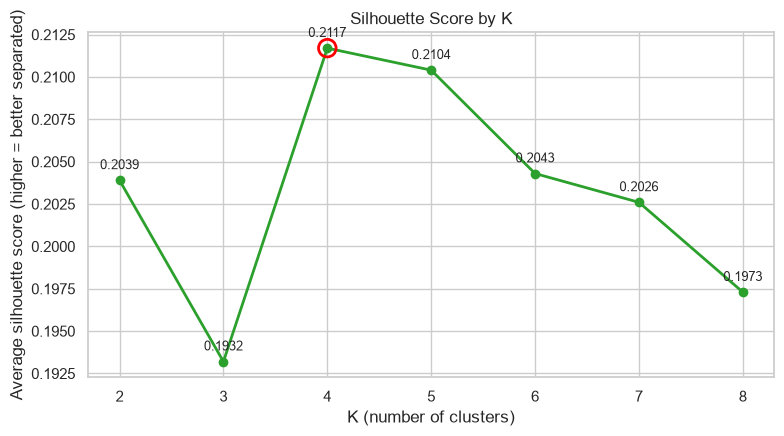

highest silhouette at K = 4


In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(results.index, results["silhouette"], marker="o", linewidth=2, color="tab:green")
best_k = results["silhouette"].idxmax()
ax.scatter([best_k], [results.loc[best_k, "silhouette"]], s=160, facecolors="none", edgecolors="red", linewidths=2, zorder=3)
for k, row in results.iterrows():
    ax.annotate(f"{row['silhouette']:.4f}", (k, row["silhouette"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_xlabel("K (number of clusters)")
ax.set_ylabel("Average silhouette score (higher = better separated)")
ax.set_title("Silhouette Score by K")
ax.set_xticks(results.index)
plt.tight_layout()
plt.show()
print("highest silhouette at K =", best_k)

## 10. Best K selection and explanation

We look at four things together, not just one number.

In [19]:
# 1) Stability: does K-Means find the same groups from different random seeds?
#    Adjusted Rand Index (ARI): 1.0 = identical grouping, 0 = no better than random.
stability = {}
for k in [3, 4, 5]:
    base = models[k].labels_
    stability[k] = [round(adjusted_rand_score(base, KMeans(n_clusters=k, random_state=s, n_init=10).fit_predict(X_scaled)), 3)
                    for s in [1, 7, 99]]
pd.DataFrame(stability, index=["seed 1", "seed 7", "seed 99"]).T.rename_axis("k")

,seed 1,seed 7,seed 99
k,,,
3,0.993,0.986,0.996
4,0.998,0.998,0.998
5,0.972,0.968,0.978


In [20]:
# 2) What do the groups look like at the candidate K values?
for k in [3, 4, 5]:
    prof = customers.assign(cluster=models[k].labels_).groupby("cluster")[FEATURES + ["total_spend"]].mean().round(2)
    prof.insert(0, "customers", np.bincount(models[k].labels_))
    print(f"--- K = {k} ---")
    display(prof)

--- K = 3 ---


,customers,frequency,recency_days,avg_order_value,avg_quantity,discount_rate,total_spend
cluster,,,,,,,
0,1643,5.85,52.90,1354.28,3.00,0.06,7813.93
1,1651,2.20,158.87,456.05,2.21,0.06,1002.68
2,1706,2.23,163.76,1955.70,3.81,0.04,4270.42


--- K = 4 ---


,customers,frequency,recency_days,avg_order_value,avg_quantity,discount_rate,total_spend
cluster,,,,,,,
0,1255,2.16,165.90,427.13,2.12,0.03,929.71
1,1433,2.36,154.92,2063.40,3.73,0.02,4755.66
2,1024,2.70,129.09,1121.57,3.12,0.14,3034.16
3,1288,6.36,51.39,1298.94,2.99,0.04,8300.02


--- K = 5 ---


,customers,frequency,recency_days,avg_order_value,avg_quantity,discount_rate,total_spend
cluster,,,,,,,
0,1271,2.72,110.13,2281.72,3.67,0.02,5831.25
1,1026,2.57,92.51,440.81,2.16,0.03,1153.86
2,1008,6.91,50.49,1293.55,3.00,0.05,9010.80
3,948,2.85,112.02,1157.39,3.13,0.14,3287.94
4,747,1.72,316.75,751.00,2.93,0.04,1317.03


### Decision: **K = 4**

| Evidence | What we see | Points to |
|---|---|---|
| **Silhouette** | Highest at K = 4 (0.2117), with K = 5 a close second (0.2104). K = 3 drops to 0.1932. | 4 (or 5) |
| **Elbow** | Inertia falls by 3,225 (2→3), 2,421 (3→4) and 1,564 (4→5), then only 1,065, 743 and 654 per extra cluster. The curve bends around K = 4–5. | 4–5 |
| **Stability** | K = 4 gives the same grouping from every random seed (ARI 0.998). K = 5 is a bit less stable (≈ 0.97). | 4 |
| **Meaning** | K = 3 lumps discount-driven shoppers in with everyone else. K = 4 separates **four clearly different behaviours**: loyal frequent buyers, big-basket buyers, discount-driven buyers and low-value occasional buyers. K = 5 mainly splits out customers who haven't bought in ~10 months. | 4 |

K = 4 wins on silhouette, sits at the elbow, is the most stable, and gives groups a marketer can act on.
**K = 5 is a reasonable alternative** if the business wants a separate "win-back lapsed customers" group.

**An honest note on quality:** a silhouette around 0.21 means the groups **overlap**. Customers sit on a
continuum rather than in clean, separate islands. That's normal for real customer behaviour. The segments are
still useful as *practical divisions* for targeting, but customers near a boundary could reasonably belong to
either neighbouring group.

## 11. Final customer clustering

In [21]:
FINAL_K = 4
final_model = KMeans(n_clusters=FINAL_K, random_state=RANDOM_STATE, n_init=10)
customers["cluster"] = final_model.fit_predict(X_scaled)

print("every customer assigned:", customers["cluster"].notna().all(), "| customers:", len(customers))
customers["cluster"].value_counts().sort_index().to_frame("customers")

every customer assigned: True | customers: 5000


,customers
cluster,
0,1255
1,1433
2,1024
3,1288


In [22]:
# Centroids translated back to real units (undo the scaling, then undo the log)
centroids = pd.DataFrame(scaler.inverse_transform(final_model.cluster_centers_), columns=FEATURES)
centroids["avg_order_value"] = np.expm1(centroids["avg_order_value"])
centroids.index.name = "cluster"
centroids.round(3)

,frequency,recency_days,avg_order_value,avg_quantity,discount_rate
cluster,,,,,
0,2.163,165.900,294.327,2.123,0.028
1,2.363,154.879,1366.977,3.733,0.017
2,2.700,129.107,698.613,3.119,0.138
3,6.359,51.281,1047.788,2.991,0.045


These are the **centroids**, the "average customer" of each group, in original units.
`scaler.inverse_transform` undoes the z-score and `np.expm1` undoes `log1p`.
(The centroid's order value is a *typical* value, so it's lower than the plain average, which the
big spenders pull up.)

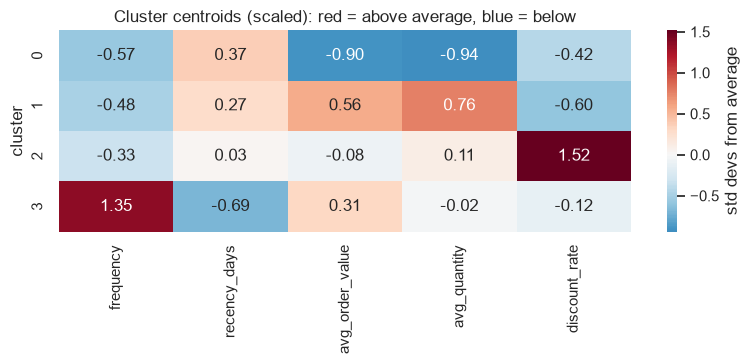

In [23]:
# Which features make each cluster different? (centroid position in standard deviations from the overall average)
z = pd.DataFrame(final_model.cluster_centers_, columns=FEATURES)
z.index.name = "cluster"
plt.figure(figsize=(8, 3.8))
sns.heatmap(z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar_kws={"label": "std devs from average"})
plt.title("Cluster centroids (scaled): red = above average, blue = below")
plt.tight_layout()
plt.show()

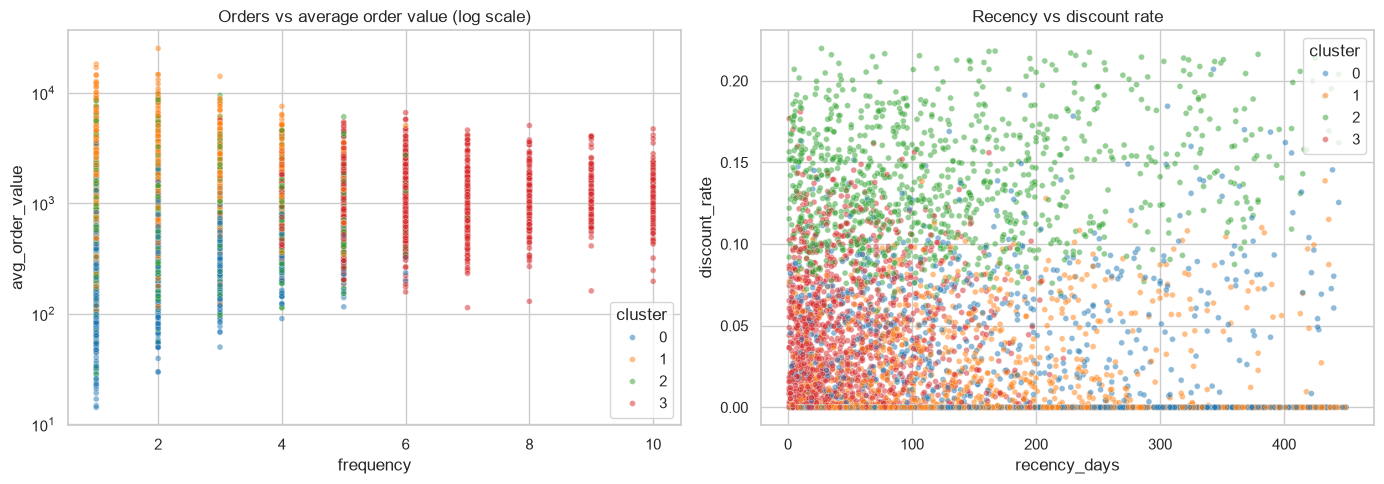

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette = sns.color_palette("tab10", FINAL_K)
sns.scatterplot(data=customers, x="frequency", y="avg_order_value", hue="cluster", palette=palette,
                alpha=0.5, s=18, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Orders vs average order value (log scale)")
sns.scatterplot(data=customers, x="recency_days", y="discount_rate", hue="cluster", palette=palette,
                alpha=0.5, s=18, ax=axes[1])
axes[1].set_title("Recency vs discount rate")
plt.tight_layout()
plt.show()

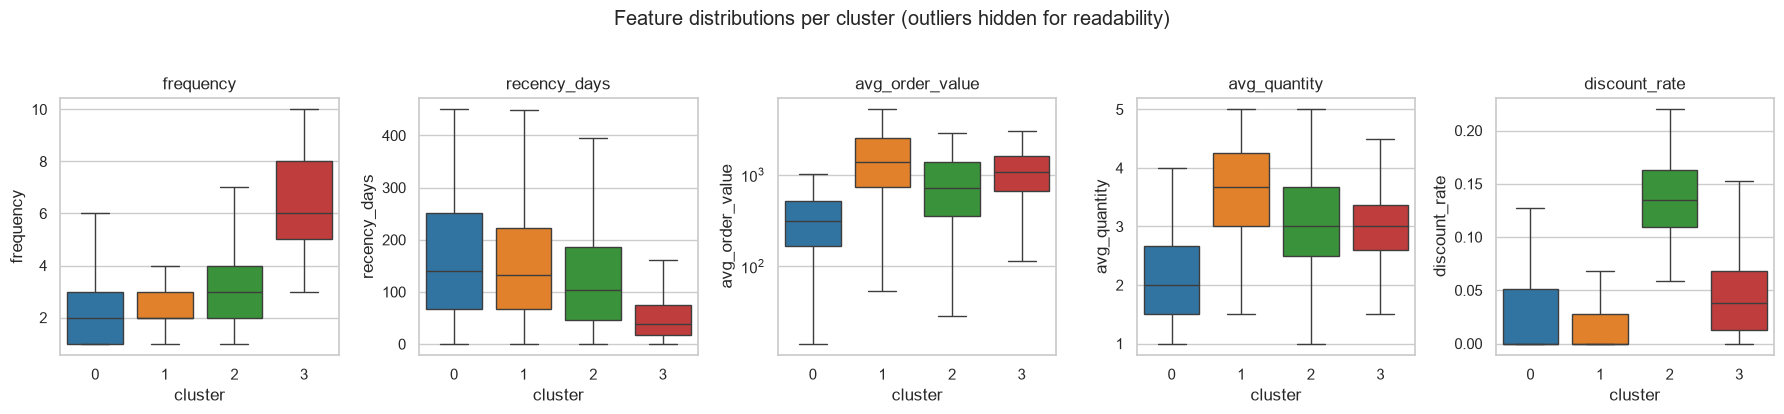

In [25]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, FEATURES):
    sns.boxplot(data=customers, x="cluster", y=col, hue="cluster", palette=palette, legend=False, ax=ax, showfliers=False)
    ax.set_title(col)
    if col == "avg_order_value":
        ax.set_yscale("log")
plt.suptitle("Feature distributions per cluster (outliers hidden for readability)", y=1.03)
plt.tight_layout()
plt.show()

## 12. Customer group descriptions

In [26]:
# Most popular product category per cluster (by number of orders)
orders = df.merge(customers[["cluster"]], left_on="Customer_ID", right_index=True)
cat_share = pd.crosstab(orders["cluster"], orders["Product_Category"], normalize="index")
top_cat = pd.DataFrame({
    "top_category": cat_share.idxmax(axis=1),
    "top_category_share_%": (cat_share.max(axis=1) * 100).round(1),
})

summary = customers.groupby("cluster").agg(
    customers=("frequency", "size"),
    avg_total_spend=("total_spend", "mean"),
    avg_order_value=("avg_order_value", "mean"),
    avg_quantity=("avg_quantity", "mean"),
    avg_frequency=("frequency", "mean"),
    avg_recency_days=("recency_days", "mean"),
    avg_discount_rate_pct=("discount_rate", lambda s: s.mean() * 100),
    avg_rating=("avg_rating", "mean"),
)
summary.insert(1, "pct_customers", (summary["customers"] / summary["customers"].sum() * 100))
summary = summary.join(top_cat).round(2)
summary

,customers,pct_customers,avg_total_spend,avg_order_value,avg_quantity,avg_frequency,avg_recency_days,avg_discount_rate_pct,avg_rating,top_category,top_category_share_%
cluster,,,,,,,,,,,
0,1255,25.10,929.71,427.13,2.12,2.16,165.90,2.77,3.94,Books,17.0
1,1433,28.66,4755.66,2063.40,3.73,2.36,154.92,1.74,3.91,Electronics,16.5
2,1024,20.48,3034.16,1121.57,3.12,2.70,129.09,13.76,3.87,Food,13.8
3,1288,25.76,8300.02,1298.94,2.99,6.36,51.39,4.47,3.88,Sports,13.5


In [27]:
# How different are the category mixes? (% of each cluster's orders)
(cat_share * 100).round(1)

Product_Category,Beauty,Books,Electronics,Fashion,Food,Home & Garden,Sports,Toys
cluster,,,,,,,,
0,15.7,17.0,5.1,12.9,14.9,9.3,10.9,14.2
1,11.1,10.8,16.5,12.1,9.1,14.2,14.8,11.3
2,13.4,13.3,12.5,11.3,13.8,11.0,12.5,12.2
3,12.7,12.3,12.6,12.0,12.3,12.5,13.5,12.0


In [28]:
# Overall averages, for comparison
overall = customers[["total_spend", "avg_order_value", "avg_quantity", "frequency", "recency_days", "discount_rate", "avg_rating"]].mean()
overall["discount_rate"] *= 100
overall.round(2).to_frame("all customers")

,all customers
total_spend,4355.81
avg_order_value,1262.89
avg_quantity,3.01
frequency,3.41
recency_days,125.72
discount_rate,5.16
avg_rating,3.90


### One line per group

These descriptions come from the summary table above. Cluster *numbers* are arbitrary (K-Means just
numbers the groups 0–3), so each group is described by its **behaviour**, not its number.

- **Cluster 0 (low-value occasional buyers, 25%):** buy rarely (≈2.2 orders), haven't bought for ≈5.5 months and place small, cheap orders (≈2.1 items, ≈427 avg order value; mostly Books, Beauty and Food, rarely Electronics), giving the lowest total spend (≈930).
- **Cluster 1 (big-basket buyers, 29%):** buy rarely (≈2.4 orders) but spend the most per order (≈2,063 avg order value, ≈3.7 items), lean towards Electronics, Home & Garden and Sports, and almost never use discounts (≈1.7%).
- **Cluster 2 (discount-driven shoppers, 20%):** mid-sized orders (≈1,122 avg value, ≈3.1 items) with by far the highest discount rate (≈13.8% off list price, 3–8× the other groups), so they're promotion-responsive buyers.
- **Cluster 3 (loyal frequent buyers, 26%):** order about 2.5× as often as the other groups (≈6.4 orders), bought most recently (≈51 days ago) and have the highest total spend (≈8,300), making them the most valuable group.

**Product category: a mild, sensible pattern.** Category wasn't a model input, yet the two groups split by order
value lean towards different categories. Electronics is 16.5% of the big-basket buyers' orders but only 5.1% of the
low-value buyers' orders, and Books is the reverse (10.8% vs 17.0%). That follows from price: Electronics has
the highest median unit price and Books the lowest. The discount-driven and loyal groups buy an almost even mix
(12.5% per category would be perfectly even). **Ratings don't separate the groups** (all ≈3.9).

## 13. Business interpretation and conclusion

**How to interpret customer clusters:** read each centroid as a "typical customer" and ask *what would we
do differently for this person?* A cluster is only useful if the answer differs between groups.

| Group | Size | What it means for marketing |
|---|---:|---|
| Loyal frequent buyers | 26% | The core: most orders, most recent, most revenue. Protect and reward them (loyalty perks, early access), and don't train them to wait for discounts. |
| Big-basket buyers | 29% | High value per order but infrequent, with a lean towards Electronics and Home & Garden. The opportunity is **frequency**: reminders, accessories and cross-sell to bring them back sooner. |
| Discount-driven shoppers | 20% | Respond to price. Target with promotions, but watch margin, since they already get ~14% off. |
| Low-value occasional buyers | 25% | Small, rare orders, long since the last one. Low-cost re-engagement and basket-building offers (bundles, free-shipping thresholds). |

**What we did**
1. Checked the data thoroughly. It was already clean, so no rows were removed and the original CSV was untouched.
2. Rolled 17,049 orders up to 5,000 customers.
3. Chose 5 purchasing-behaviour features (an RFM view plus basket size and discount sensitivity), dropping
   redundant ones (unit price, total spend) and noise-like ones (rating, session, pages, delivery), and showed with
   data that adding the noise-like ones hurts.
4. Log-transformed order value, then standardised all features.
5. Ran K-Means for K = 2–8 and picked **K = 4** from silhouette, elbow, stability and meaning.
6. Assigned every customer a cluster and described each group.

**Limitations**
- Silhouette ≈ 0.21: the groups overlap, so treat the boundaries as soft.
- Recency depends on the cut-off date (day after the last order, 2024-03-26).
- Category preferences are only mild (top category ≤ 17% of a group's orders), so messaging shouldn't rely on one category per group.

**Output:** the cluster assignment for every customer is saved to `data/processed/customer_segments.csv`,
for use on Day 4.

In [29]:
OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
customers.reset_index()[["Customer_ID", "cluster"] + FEATURES + ["total_spend", "avg_rating"]].to_csv(OUT_PATH, index=False)
print("saved", OUT_PATH.relative_to(ROOT), "-", len(customers), "customers")

saved data\processed\customer_segments.csv - 5000 customers
